<a href="https://colab.research.google.com/github/AnishShrestha09/student_placement_analysis_prject/blob/main/Student_Placement_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files

uploaded = files.upload()

Saving train.csv to train.csv


In [2]:
import pandas as pd

df = pd.read_csv("train.csv")

In [3]:
df.head()

,CGPA,Internships,Projects,Workshops/Certifications,AptitudeTestScore,SoftSkillsRating,ExtracurricularActivities,PlacementTraining,SSC_Marks,HSC_Marks,PlacementStatus
0,7.7,1,1,0,69,4.0,No,No,55,69,NotPlaced
1,7.6,2,3,1,80,4.3,Yes,Yes,57,70,NotPlaced
2,7.0,1,1,1,64,4.1,No,No,58,62,NotPlaced
3,7.9,1,3,2,90,4.8,Yes,Yes,82,80,Placed
4,6.7,0,2,1,71,3.7,No,No,55,67,NotPlaced


In [4]:
# check the columns

In [5]:
list[df.columns]

list[Index(['CGPA', 'Internships', 'Projects', 'Workshops/Certifications',
       'AptitudeTestScore', 'SoftSkillsRating', 'ExtracurricularActivities',
       'PlacementTraining', 'SSC_Marks', 'HSC_Marks', 'PlacementStatus'],
      dtype='object')]

In [6]:
# feature enginnering

In [7]:
from numpy import place
X = df.drop("PlacementStatus", axis = 1)
Y = df["PlacementStatus"]

In [8]:
X.head()

,CGPA,Internships,Projects,Workshops/Certifications,AptitudeTestScore,SoftSkillsRating,ExtracurricularActivities,PlacementTraining,SSC_Marks,HSC_Marks
0,7.7,1,1,0,69,4.0,No,No,55,69
1,7.6,2,3,1,80,4.3,Yes,Yes,57,70
2,7.0,1,1,1,64,4.1,No,No,58,62
3,7.9,1,3,2,90,4.8,Yes,Yes,82,80
4,6.7,0,2,1,71,3.7,No,No,55,67


In [9]:
Y.head()

,PlacementStatus
0,NotPlaced
1,NotPlaced
2,NotPlaced
3,Placed
4,NotPlaced


In [10]:
# to check the size of dataset

In [11]:
df.shape

(7225, 11)

In [12]:
# details of the dataframe
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7225 entries, 0 to 7224
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   CGPA                       7225 non-null   float64
 1   Internships                7225 non-null   int64  
 2   Projects                   7225 non-null   int64  
 3   Workshops/Certifications   7225 non-null   int64  
 4   AptitudeTestScore          7225 non-null   int64  
 5   SoftSkillsRating           7225 non-null   float64
 6   ExtracurricularActivities  7225 non-null   object 
 7   PlacementTraining          7225 non-null   object 
 8   SSC_Marks                  7225 non-null   int64  
 9   HSC_Marks                  7225 non-null   int64  
 10  PlacementStatus            7225 non-null   object 
dtypes: float64(2), int64(6), object(3)
memory usage: 621.0+ KB


In [13]:
df.head()

,CGPA,Internships,Projects,Workshops/Certifications,AptitudeTestScore,SoftSkillsRating,ExtracurricularActivities,PlacementTraining,SSC_Marks,HSC_Marks,PlacementStatus
0,7.7,1,1,0,69,4.0,No,No,55,69,NotPlaced
1,7.6,2,3,1,80,4.3,Yes,Yes,57,70,NotPlaced
2,7.0,1,1,1,64,4.1,No,No,58,62,NotPlaced
3,7.9,1,3,2,90,4.8,Yes,Yes,82,80,Placed
4,6.7,0,2,1,71,3.7,No,No,55,67,NotPlaced


In [14]:
# diiferent status of a placement

In [15]:
df["PlacementStatus"].unique()

array(['NotPlaced', 'Placed'], dtype=object)

In [16]:
# to check how many have placed and notplaced in trainning data

In [17]:
df["PlacementStatus"].value_counts()

,count
PlacementStatus,
NotPlaced,4193
Placed,3032


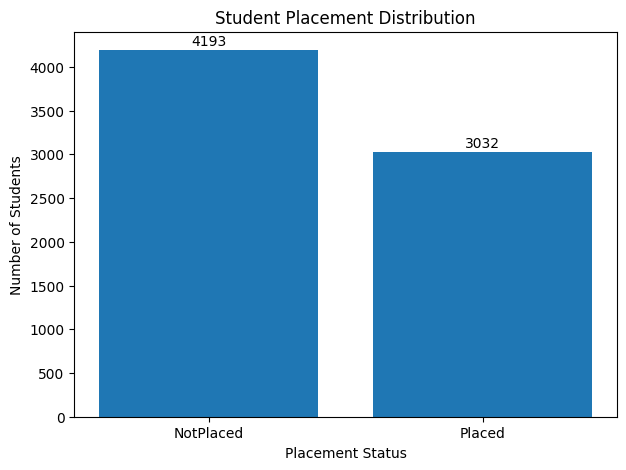

In [18]:
import matplotlib.pyplot as plt

# Count each placement category
placement_counts = df["PlacementStatus"].value_counts()

# Create bar chart
plt.figure(figsize=(7, 5))
plt.bar(placement_counts.index, placement_counts.values)

# Add labels and title
plt.title("Student Placement Distribution")
plt.xlabel("Placement Status")
plt.ylabel("Number of Students")

# Display count above each bar
for i, count in enumerate(placement_counts.values):
    plt.text(i, count + 50, str(count), ha="center")

plt.show()

In [19]:
# checking catefgorical values


In [20]:
df["ExtracurricularActivities"].value_counts()

,count
ExtracurricularActivities,
Yes,4245
No,2980


In [21]:
df["PlacementTraining"].value_counts()

,count
PlacementTraining,
Yes,5270
No,1955


In [22]:
df.duplicated().sum()

np.int64(43)

In [23]:
df[df.duplicated()]

,CGPA,Internships,Projects,Workshops/Certifications,AptitudeTestScore,SoftSkillsRating,ExtracurricularActivities,PlacementTraining,SSC_Marks,HSC_Marks,PlacementStatus
1265,8.1,2,3,2,90,4.7,Yes,Yes,78,82,Placed
1327,8.3,2,3,2,90,4.8,Yes,Yes,83,85,Placed
1474,8.3,2,3,2,90,4.8,Yes,Yes,80,84,Placed
2085,7.9,2,3,2,90,4.8,Yes,Yes,82,88,Placed
2087,8.5,2,3,2,90,4.8,Yes,Yes,82,87,Placed
3302,8.5,2,3,2,90,4.8,Yes,Yes,82,87,Placed
3312,8.1,2,3,2,90,4.8,Yes,Yes,84,86,Placed
3348,8.5,1,3,2,90,4.8,Yes,Yes,76,85,Placed
3383,8.2,2,3,2,90,4.8,Yes,Yes,83,87,Placed
3543,8.3,2,3,2,90,4.8,Yes,Yes,78,87,Placed


In [24]:
df[df.duplicated()].shape[0]

43

In [25]:
# check the duplicate percentage

In [26]:
(df.duplicated().sum() / len(df)) * 100


np.float64(0.5951557093425606)

In [27]:
df = df.drop_duplicates()

In [28]:
df.head()

,CGPA,Internships,Projects,Workshops/Certifications,AptitudeTestScore,SoftSkillsRating,ExtracurricularActivities,PlacementTraining,SSC_Marks,HSC_Marks,PlacementStatus
0,7.7,1,1,0,69,4.0,No,No,55,69,NotPlaced
1,7.6,2,3,1,80,4.3,Yes,Yes,57,70,NotPlaced
2,7.0,1,1,1,64,4.1,No,No,58,62,NotPlaced
3,7.9,1,3,2,90,4.8,Yes,Yes,82,80,Placed
4,6.7,0,2,1,71,3.7,No,No,55,67,NotPlaced


In [29]:
df.shape

(7182, 11)

In [30]:
df.duplicated().sum()

np.int64(0)

In [31]:
X = df.drop("PlacementStatus", axis=1)

y = df["PlacementStatus"]

In [32]:
X.shape

(7182, 10)

In [33]:
y.shape

(7182,)

In [34]:
y.value_counts()

,count
PlacementStatus,
NotPlaced,4192
Placed,2990


In [35]:
# checking if there is missing values in any columns

In [36]:
df.isna().sum()

,0
CGPA,0
Internships,0
Projects,0
Workshops/Certifications,0
AptitudeTestScore,0
SoftSkillsRating,0
ExtracurricularActivities,0
PlacementTraining,0
SSC_Marks,0
HSC_Marks,0


## part of encoding


In [37]:
X.dtypes

,0
CGPA,float64
Internships,int64
Projects,int64
Workshops/Certifications,int64
AptitudeTestScore,int64
SoftSkillsRating,float64
ExtracurricularActivities,object
PlacementTraining,object
SSC_Marks,int64
HSC_Marks,int64


In [38]:
x_encoded = X.copy()

In [39]:
x_encoded["ExtracurricularActivities"].head()

,ExtracurricularActivities
0,No
1,Yes
2,No
3,Yes
4,No


In [40]:
x_encoded["ExtracurricularActivities"].value_counts()

,count
ExtracurricularActivities,
Yes,4203
No,2979


In [41]:
x_encoded["ExtracurricularActivities"] = x_encoded["ExtracurricularActivities"].map({"Yes":1,"No":0})

In [42]:
x_encoded["ExtracurricularActivities"].head()

,ExtracurricularActivities
0,0
1,1
2,0
3,1
4,0


In [43]:
x_encoded.head()

,CGPA,Internships,Projects,Workshops/Certifications,AptitudeTestScore,SoftSkillsRating,ExtracurricularActivities,PlacementTraining,SSC_Marks,HSC_Marks
0,7.7,1,1,0,69,4.0,0,No,55,69
1,7.6,2,3,1,80,4.3,1,Yes,57,70
2,7.0,1,1,1,64,4.1,0,No,58,62
3,7.9,1,3,2,90,4.8,1,Yes,82,80
4,6.7,0,2,1,71,3.7,0,No,55,67


In [44]:
x_encoded.dtypes

,0
CGPA,float64
Internships,int64
Projects,int64
Workshops/Certifications,int64
AptitudeTestScore,int64
SoftSkillsRating,float64
ExtracurricularActivities,int64
PlacementTraining,object
SSC_Marks,int64
HSC_Marks,int64


In [45]:
x_encoded["PlacementTraining"].value_counts()

,count
PlacementTraining,
Yes,5227
No,1955


In [46]:
#  encoding of placement column

In [47]:
x_encoded["PlacementTraining"] = x_encoded["PlacementTraining"].map({"Yes": 1, "No": 0})

In [48]:
x_encoded.dtypes

,0
CGPA,float64
Internships,int64
Projects,int64
Workshops/Certifications,int64
AptitudeTestScore,int64
SoftSkillsRating,float64
ExtracurricularActivities,int64
PlacementTraining,int64
SSC_Marks,int64
HSC_Marks,int64


In [49]:
from google.colab import files
files.upload()

Saving validation.csv to validation.csv


{'validation.csv': b'CGPA,Internships,Projects,Workshops/Certifications,AptitudeTestScore,SoftSkillsRating,ExtracurricularActivities,PlacementTraining,SSC_Marks,HSC_Marks,PlacementStatus\n7.8,2,1,1,78,4.1,Yes,Yes,62,61,Placed\n6.6,1,3,3,65,4.2,Yes,Yes,55,86,Placed\n8.1,1,3,2,90,4.8,Yes,Yes,79,84,Placed\n7.5,1,2,1,73,4.4,No,Yes,69,79,NotPlaced\n8.8,2,3,2,90,4.8,Yes,Yes,70,79,Placed\n8.2,0,2,1,83,4.8,No,Yes,71,65,NotPlaced\n6.7,1,1,1,60,3.3,No,Yes,62,69,Placed\n8.1,1,2,1,73,4.2,No,Yes,83,87,NotPlaced\n7.1,0,3,2,90,4.8,Yes,Yes,74,87,Placed\n8.0,2,2,2,85,4.5,Yes,Yes,79,81,NotPlaced\n6.5,1,2,0,74,4.1,No,Yes,55,59,NotPlaced\n6.5,0,1,0,71,3.7,No,Yes,71,65,NotPlaced\n7.4,0,2,1,79,3.6,No,Yes,55,65,NotPlaced\n8.4,2,3,2,90,4.8,Yes,Yes,80,85,Placed\n8.3,1,3,1,83,4.8,Yes,No,65,80,NotPlaced\n8.1,2,3,2,86,4.8,No,Yes,79,81,Placed\n7.1,2,3,2,88,4.7,Yes,Yes,76,86,Placed\n8.1,0,3,0,76,3.9,Yes,Yes,66,83,NotPlaced\n7.5,0,3,0,88,4.4,Yes,Yes,67,86,NotPlaced\n7.7,2,1,0,74,3.6,Yes,Yes,69,70,NotPlaced\n7.8,2,3,

In [50]:
validation_df = pd.read_csv("validation.csv")

In [51]:
validation_df.head()

,CGPA,Internships,Projects,Workshops/Certifications,AptitudeTestScore,SoftSkillsRating,ExtracurricularActivities,PlacementTraining,SSC_Marks,HSC_Marks,PlacementStatus
0,7.8,2,1,1,78,4.1,Yes,Yes,62,61,Placed
1,6.6,1,3,3,65,4.2,Yes,Yes,55,86,Placed
2,8.1,1,3,2,90,4.8,Yes,Yes,79,84,Placed
3,7.5,1,2,1,73,4.4,No,Yes,69,79,NotPlaced
4,8.8,2,3,2,90,4.8,Yes,Yes,70,79,Placed


In [52]:
validation_df.head().dtypes


,0
CGPA,float64
Internships,int64
Projects,int64
Workshops/Certifications,int64
AptitudeTestScore,int64
SoftSkillsRating,float64
ExtracurricularActivities,object
PlacementTraining,object
SSC_Marks,int64
HSC_Marks,int64


In [53]:
X_val = validation_df.drop("PlacementStatus", axis=1)
y_val = validation_df["PlacementStatus"]

In [54]:
X_val.columns

Index(['CGPA', 'Internships', 'Projects', 'Workshops/Certifications',
       'AptitudeTestScore', 'SoftSkillsRating', 'ExtracurricularActivities',
       'PlacementTraining', 'SSC_Marks', 'HSC_Marks'],
      dtype='object')

In [55]:
y_val.head(4)

,PlacementStatus
0,Placed
1,Placed
2,Placed
3,NotPlaced


In [56]:
y_val.head()

,PlacementStatus
0,Placed
1,Placed
2,Placed
3,NotPlaced
4,Placed


In [57]:
X_val_encoded = X_val.copy()

X_val_encoded["ExtracurricularActivities"] = X_val_encoded["ExtracurricularActivities"].map({"Yes": 1, "No": 0})

X_val_encoded["PlacementTraining"] = X_val_encoded["PlacementTraining"].map({"Yes": 1, "No": 0})

In [58]:
X_val_encoded.dtypes

,0
CGPA,float64
Internships,int64
Projects,int64
Workshops/Certifications,int64
AptitudeTestScore,int64
SoftSkillsRating,float64
ExtracurricularActivities,int64
PlacementTraining,int64
SSC_Marks,int64
HSC_Marks,int64


In [59]:
# check if the columns are in the same place

In [60]:
x_encoded.columns.equals(X_val_encoded.columns)

True

In [61]:
y.head()

,PlacementStatus
0,NotPlaced
1,NotPlaced
2,NotPlaced
3,Placed
4,NotPlaced


In [62]:
#  machine learning part

In [63]:
from sklearn.linear_model import LogisticRegression

In [64]:
model = LogisticRegression()

In [65]:
model.fit(x_encoded, y)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [66]:
y_pred = model.predict(X_val_encoded)

In [67]:
y_pred[:10]

array(['NotPlaced', 'Placed', 'Placed', 'NotPlaced', 'Placed',
       'NotPlaced', 'NotPlaced', 'NotPlaced', 'Placed', 'Placed'],
      dtype=object)

In [68]:
y_val[:10]

,PlacementStatus
0,Placed
1,Placed
2,Placed
3,NotPlaced
4,Placed
5,NotPlaced
6,Placed
7,NotPlaced
8,Placed
9,NotPlaced


In [69]:
from sklearn.metrics import accuracy_score

In [70]:
accuracy_score(y_val, y_pred)

0.7678431372549019

In [71]:
from sklearn.metrics import confusion_matrix

In [72]:
confusion_matrix(y_val, y_pred)

array([[589, 151],
       [145, 390]])

In [73]:
from sklearn.metrics import precision_score

precision_score(y_val, y_pred, pos_label="Placed")

0.7208872458410351

In [74]:
model.predict_proba(X_val_encoded[:5])

array([[0.5648055 , 0.4351945 ],
       [0.19022838, 0.80977162],
       [0.19511277, 0.80488723],
       [0.79779298, 0.20220702],
       [0.18598208, 0.81401792]])

In [75]:
model.classes_


array(['NotPlaced', 'Placed'], dtype=object)

In [76]:
accuracy_score(y, model.predict(x_encoded))

0.7687273739905319

In [77]:
model.coef_

array([[-0.19102633,  0.21704183,  0.87352011,  0.32217458,  0.03479292,
        -0.72784751,  1.37857228,  0.94331733,  0.00557405, -0.00521012]])

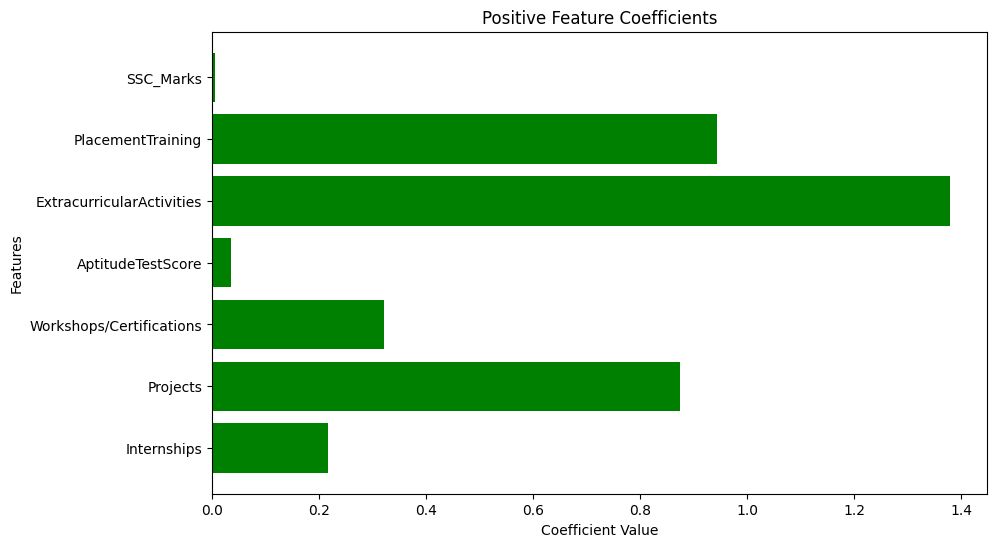

In [78]:
import matplotlib.pyplot as plt

coefficients = model.coef_[0]

positive_mask = coefficients > 0

positive_features = x_encoded.columns[positive_mask]
positive_values = coefficients[positive_mask]

plt.figure(figsize=(10, 6))

plt.barh(positive_features, positive_values, color='green')

plt.title("Positive Feature Coefficients")
plt.xlabel("Coefficient Value")
plt.ylabel("Features")

plt.show()

In [79]:
from sklearn.preprocessing import StandardScaler

# We create a StandardScaler object and store it in the variable scaler
scaler = StandardScaler()

In [80]:
scaler.fit(x_encoded)

StandardScaler()

In [81]:
X_train_scaled = scaler.transform(x_encoded)

In [82]:
X_train_scaled[:5]

array([[ 0.00317045, -0.06562555, -1.1776908 , -1.1209175 , -1.27858755,
        -0.7879984 , -1.18780307, -1.63513219, -1.353255  , -0.60710957],
       [-0.15386533,  1.44019787,  1.12824577, -0.01402495,  0.07245871,
        -0.05557903,  0.8418904 ,  0.61157135, -1.16173288, -0.49462154],
       [-1.09608003, -0.06562555, -1.1776908 , -0.01402495, -1.89269949,
        -0.54385861, -1.18780307, -1.63513219, -1.06597182, -1.39452577],
       [ 0.31724202, -0.06562555,  1.12824577,  1.09286759,  1.30068258,
         1.16511993,  0.8418904 ,  0.61157135,  1.23229366,  0.63025874],
       [-1.56718738, -1.57144898, -0.02472252, -0.01402495, -1.03294278,
        -1.52041777, -1.18780307, -1.63513219, -1.353255  , -0.83208563]])

In [83]:
X_val_scaled = scaler.transform(X_val_encoded)

In [84]:
scaled_model = LogisticRegression()

In [85]:
scaled_model.fit(X_train_scaled, y)

LogisticRegression()

In [86]:
y_pred_scaled = scaled_model.predict(X_val_scaled)

In [87]:
accuracy_score(y_val, y_pred_scaled)

0.8

In [88]:
confusion_matrix(y_val, y_pred_scaled)

array([[608, 132],
       [123, 412]])

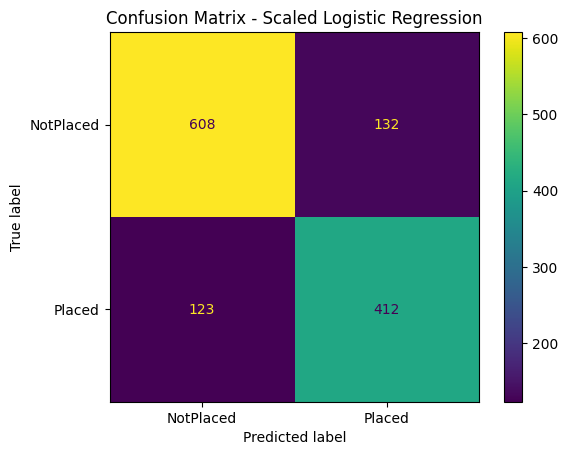

In [89]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(y_val, y_pred_scaled)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["NotPlaced", "Placed"]
)

disp.plot()

plt.title("Confusion Matrix - Scaled Logistic Regression")
plt.show()

In [90]:
from sklearn.metrics import classification_report

print(classification_report(y_val, y_pred_scaled))

              precision    recall  f1-score   support

   NotPlaced       0.83      0.82      0.83       740
      Placed       0.76      0.77      0.76       535

    accuracy                           0.80      1275
   macro avg       0.79      0.80      0.80      1275
weighted avg       0.80      0.80      0.80      1275



In [91]:
scaled_model.fit(X_train_scaled, y)

LogisticRegression()

In [92]:
import joblib

joblib.dump(scaled_model, "placement_model.pkl")

['placement_model.pkl']

In [93]:
joblib.dump(scaler, "scaler.pkl")

['scaler.pkl']

In [94]:
loaded_model = joblib.load("placement_model.pkl")

In [95]:
loaded_scaler = joblib.load("scaler.pkl")

In [96]:
print(loaded_model)
print(loaded_scaler)

LogisticRegression()
StandardScaler()
